<a href="https://colab.research.google.com/github/malachifletcher/bafad-research-track/blob/main/task-a/task_a_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task A — Exploratory Data Analysis: SMAP Telemetry
> **BAFAD Accelerated Research Track · Fall 2026**

In this notebook you will explore a sample of telemetry data drawn from NASA's Soil Moisture Active Passive (SMAP) satellite — the same dataset used in the BAFAD anomaly-detection research project.

**Your job:** Complete every cell marked `# YOUR CODE HERE`. Read the instructions carefully; output cells show what a correct result looks like.

**Submission:** Push your completed notebook to your fork of the starter repository and paste the repo URL into the Canvas assignment.

## 1 · Setup and Data Loading

Run this cell as-is — it loads all required libraries and reads the data.

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Fixed style matching STAT 270 colour scheme
NAVY  = '#021B3A'
BLUE  = '#0EA5E9'
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False})

# Load the sample dataset
df = pd.read_csv('/content/smap_sample.csv')
print(f'Loaded: {df.shape[0]} rows × {df.shape[1]} columns')

Loaded: 500 rows × 27 columns


## 2 · First Look at the Data

**A. (2 pts)** Use `.info()` and `.describe()` to inspect the dataset. In the markdown cell below, answer:
- How many telemetry channels are there?
- What does the `anomaly` column represent?
- Are there any missing values?

In [8]:
# YOUR CODE HERE — call df.info() and df.describe()
df.info()
df.describe()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 27 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   timestamp  500 non-null    int64  
 1   chan_00    500 non-null    float64
 2   chan_01    500 non-null    float64
 3   chan_02    500 non-null    float64
 4   chan_03    500 non-null    float64
 5   chan_04    500 non-null    float64
 6   chan_05    500 non-null    float64
 7   chan_06    500 non-null    float64
 8   chan_07    500 non-null    float64
 9   chan_08    500 non-null    float64
 10  chan_09    500 non-null    float64
 11  chan_10    500 non-null    float64
 12  chan_11    500 non-null    float64
 13  chan_12    500 non-null    float64
 14  chan_13    500 non-null    float64
 15  chan_14    500 non-null    float64
 16  chan_15    500 non-null    float64
 17  chan_16    500 non-null    float64
 18  chan_17    500 non-null    float64
 19  chan_18    500 non-null    float64
 20  chan_19   

,0
timestamp,0
chan_00,0
chan_01,0
chan_02,0
chan_03,0
chan_04,0
chan_05,0
chan_06,0
chan_07,0
chan_08,0


**Your answer (2–4 sentences):**

> _Write here._

## 3 · Anomaly Prevalence

**B. (3 pts)** Compute the number and percentage of timesteps labelled as anomalies (`anomaly == 1`).
Print a sentence like: *'X of 500 timesteps are anomalies (Y.Y%).'*

In [13]:
# YOUR CODE HERE
n_anomaly = (df['anomaly'] == 1).sum()
pct       = (n_anomaly / len(df)) * 100
print(f'{n_anomaly} of {len(df)} timesteps are anomalies ({pct:.1f}%).')

24 of 500 timesteps are anomalies (4.8%).


## 4 · Time-Series Visualisation

**C. (5 pts)** Plot `chan_00` (y-axis) against `timestamp` (x-axis) as a line chart.
- Use `NAVY` for normal timesteps and mark anomalies as red scatter points (`'r.'`, size 8).
- Label axes and add a title: *'SMAP Channel 00 — Telemetry with Anomalies Highlighted'*.
- Apply `plt.tight_layout()`.

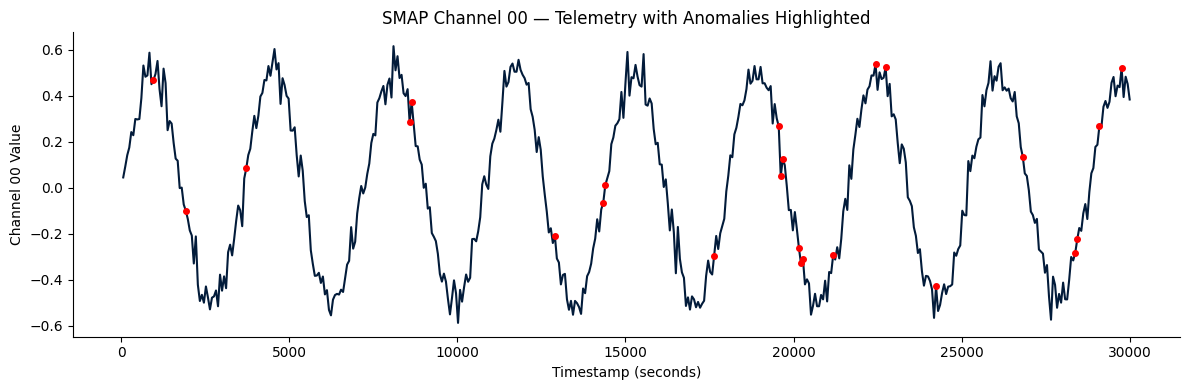

In [10]:
fig, ax = plt.subplots(figsize=(12, 4))

# YOUR CODE HERE — plot the line, then overlay anomaly markers
ax.plot(df['timestamp'], df['chan_00'], color=NAVY)

ax.plot(
    df.loc[df['anomaly'] == 1, 'timestamp'],
    df.loc[df['anomaly'] == 1, 'chan_00'],
    'r.',
    markersize=8
)
ax.set_xlabel('Timestamp (seconds)')
ax.set_ylabel('Channel 00 Value')
ax.set_title('SMAP Channel 00 — Telemetry with Anomalies Highlighted')
plt.tight_layout()
plt.show()

## 5 · Multi-Channel Heatmap

**D. (5 pts)** Create a heatmap showing all 25 telemetry channels over time.
- Rows = channels (`chan_00` … `chan_24`), columns = timesteps.
- Use `plt.imshow()` with `aspect='auto'`, `cmap='RdBu_r'`, and `vmin=-2, vmax=2`.
- Add a colourbar labelled *'Normalised Value'*.
- Draw a thin red vertical line at each anomaly timestamp.

*Hint:* Extract channel columns with `df.filter(like='chan_')`. Transpose so channels are on the y-axis.

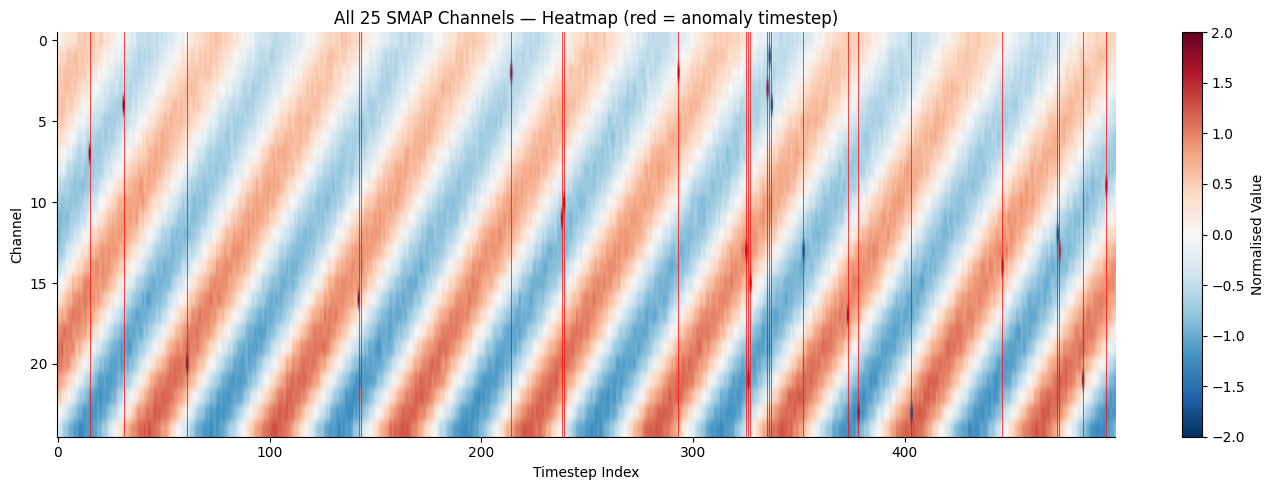

In [15]:
chan_cols = df.filter(like='chan_').columns.tolist()
data_matrix = df[chan_cols].values.T  # shape: (25 channels, 500 timesteps)

fig, ax = plt.subplots(figsize=(14, 5))

# YOUR CODE HERE — imshow, colourbar, anomaly lines
im = ax.imshow(
    data_matrix,
    aspect='auto',
    cmap='RdBu_r',
    vmin=-2,
    vmax=2
)

cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Normalised Value')

anomaly_indices = np.where(df['anomaly'] == 1)[0]

for idx in anomaly_indices:
    ax.axvline(x=idx, color='red', linewidth=0.5)
ax.set_xlabel('Timestep Index')
ax.set_ylabel('Channel')
ax.set_title('All 25 SMAP Channels — Heatmap (red = anomaly timestep)')
plt.tight_layout()
plt.show()

## 6 · Distribution of Channel Values

**E. (5 pts)** For `chan_00`, plot a histogram of values for **normal** timesteps vs **anomaly** timesteps side-by-side (use `alpha=0.6`).
- Use `NAVY` for normal, `BLUE` for anomaly.
- Add a legend and axis labels.

What do you notice about the two distributions?

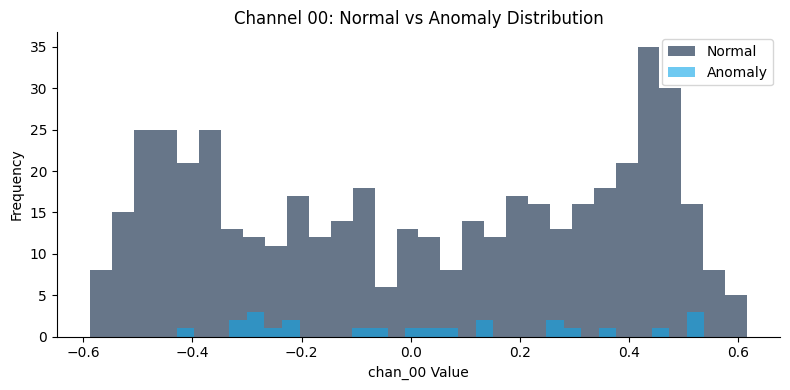

In [16]:
normal  = df[df['anomaly'] == 0]['chan_00']
anomaly = df[df['anomaly'] == 1]['chan_00']

fig, ax = plt.subplots(figsize=(8, 4))

# YOUR CODE HERE — two overlapping histograms
ax.hist(
    normal,
    bins=30,
    alpha=0.6,
    color=NAVY,
    label='Normal'
)

ax.hist(
    anomaly,
    bins=30,
    alpha=0.6,
    color=BLUE,
    label='Anomaly'
)

ax.set_xlabel('chan_00 Value')
ax.set_ylabel('Frequency')
ax.set_title('Channel 00: Normal vs Anomaly Distribution')
ax.legend()
plt.tight_layout()
plt.show()

**Your observation:**


The normal timesteps have a much higher frequency than the anomaly timesteps. The anomaly values overlap with the normal distribution, so channel 00 alone may not be enough to identify every anomaly.

## 7 · Reflection (2 pts)

Answer in the cell below (3–5 sentences total):

1. What surprised you most about the SMAP telemetry data?
2. How might the EDA patterns you observed here guide the design of an anomaly-detection model?

**Your reflection:**

> I was surprised that only 4.8% of the timesteps were labeled as anomalies. The heatmap showed that anomalies can be examined across multiple telemetry channels. The histogram also showed that anomaly values overlap with normal values, making them harder to distinguish using only one channel. An anomaly-detection model could use patterns across multiple channels and changes over time to identify unusual behavior more effectively.